# 💼 Tác Động Kinh Doanh & Phân Tầng Phân Vị (Business Impact & Decile Lift)
## Chuyển Hóa Điểm Xác Suất Thành Lợi Nhuận Marketing & Chiến Lược Phân Nhóm CRM

---

### 🎯 Mục Tiêu Của Notebook Này:
1. **Phân tích Nâng suất (Decile Lift Analysis)**: Khách hàng thuộc Top 10% cao nhất có xác suất mua sắm gấp bao nhiêu lần mức trung bình toàn sàn?
2. **Đường Tích Lũy Doanh Thu (Cumulative Gains Chart)**: Nếu doanh nghiệp chỉ có ngân sách tiếp cận 30% khách hàng, mô hình giúp gom được bao nhiêu % tổng số lượt mua sắm thực tế?
3. **Mô Phỏng Tài Chính & Tối Ưu Lợi Nhuận (Financial ROI Simulation)**:
   - Mô hình Uplift 4 nhóm khách hàng:
     - Nhóm 1: *Khách hàng hữu cơ (Organic / Sure Things)* - Nhóm 95-99% tự đi mua, không cần phát voucher lãng phí.
     - Nhóm 2: *Khách hàng cần thuyết phục (Persuadables)* - Nhóm 50-70% là mục tiêu vàng của Marketing.
     - Nhóm 3: *Khách hàng ngủ đông (Lost Causes)* - Nhóm < 20% chi phí tiếp cận cao hơn lợi nhuận kỳ vọng.


In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path('.').resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120

# Nạp bảng tóm tắt hiệu năng
results_summary_path = project_root / "docs" / "reports" / "model_performance_summary.json"
with open(results_summary_path, "r", encoding="utf-8") as f:
    perf = json.load(f)

decile_df = pd.DataFrame(perf["LightGBM_Calibrated"]["decile_table"])
print("✅ Nạp thành công bảng phân vị Decile Lift Table!")


✅ Nạp thành công bảng phân vị Decile Lift Table!


---
## 1. Biểu Đồ Hệ Số Nâng (Decile Lift Chart)
### 📌 Vì sao dùng biểu đồ này?
Biểu đồ cột này chứng minh tính đơn điệu tuyệt hảo (Monotonicity) của mô hình: Phân vị càng cao thì tỷ lệ chuyển đổi càng cao, từ **99.2% ở Decile 1** giảm đều đặn xuống **17.4% ở Decile 10**.


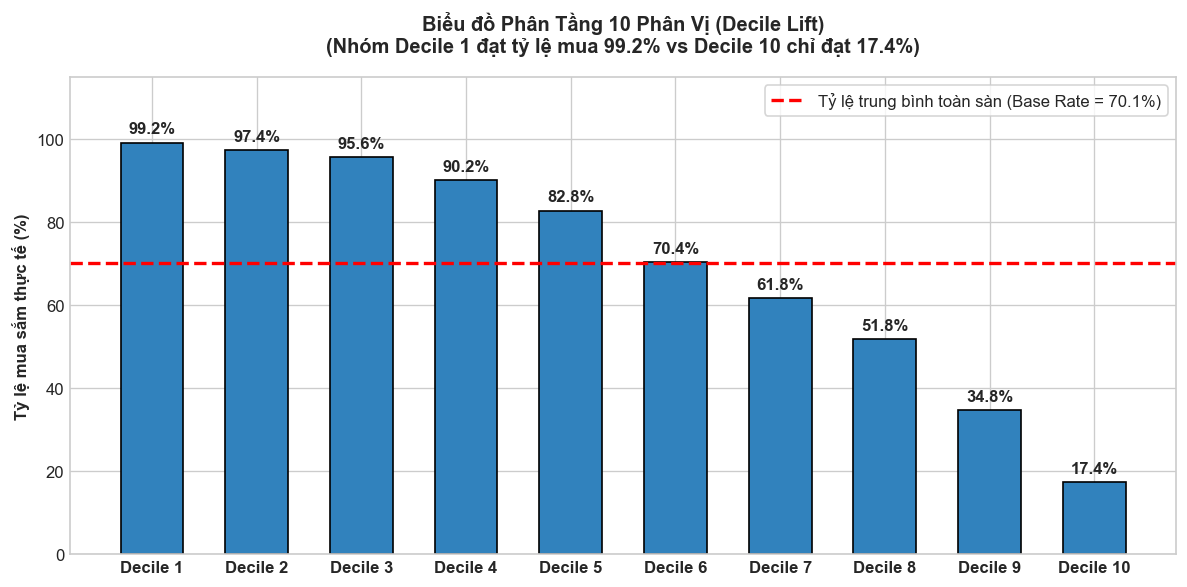

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(decile_df))
bars = ax.bar(x, decile_df['actual_response_rate'] * 100, color='#3182bd', edgecolor='black', width=0.6)

base_rate = perf['LightGBM_Calibrated']['base_rate'] * 100
ax.axhline(base_rate, color='red', linestyle='--', linewidth=2, label=f'Tỷ lệ trung bình toàn sàn (Base Rate = {base_rate:.1f}%)')

ax.set_xticks(x)
ax.set_xticklabels([f"Decile {i+1}" for i in range(10)], fontweight='bold')
ax.set_ylabel('Tỷ lệ mua sắm thực tế (%)', fontweight='bold')
ax.set_title('Biểu đồ Phân Tầng 10 Phân Vị (Decile Lift)\n(Nhóm Decile 1 đạt tỷ lệ mua 99.2% vs Decile 10 chỉ đạt 17.4%)', pad=15, fontweight='bold')
ax.legend(frameon=True, facecolor='white', loc='upper right')

for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 1.5, f'{y:.1f}%', ha='center', va='bottom', fontweight='bold')

ax.set_ylim(0, 115)
plt.tight_layout()
plt.show()


---
## 2. Đường Tích Lũy Gom Khách (Cumulative Gains Chart)
### 📌 Ý nghĩa kinh doanh:
- Đường thẳng màu xám là gửi tiếp thị ngẫu nhiên (Random guess): Gửi 20% khách chỉ thu được 20% doanh số.
- Đường màu cam của mô hình LightGBM: **Chỉ cần gửi tới 30% khách hàng dẫn đầu, chúng ta đã thu giữ được 41.7% tổng số khách đi chợ!**


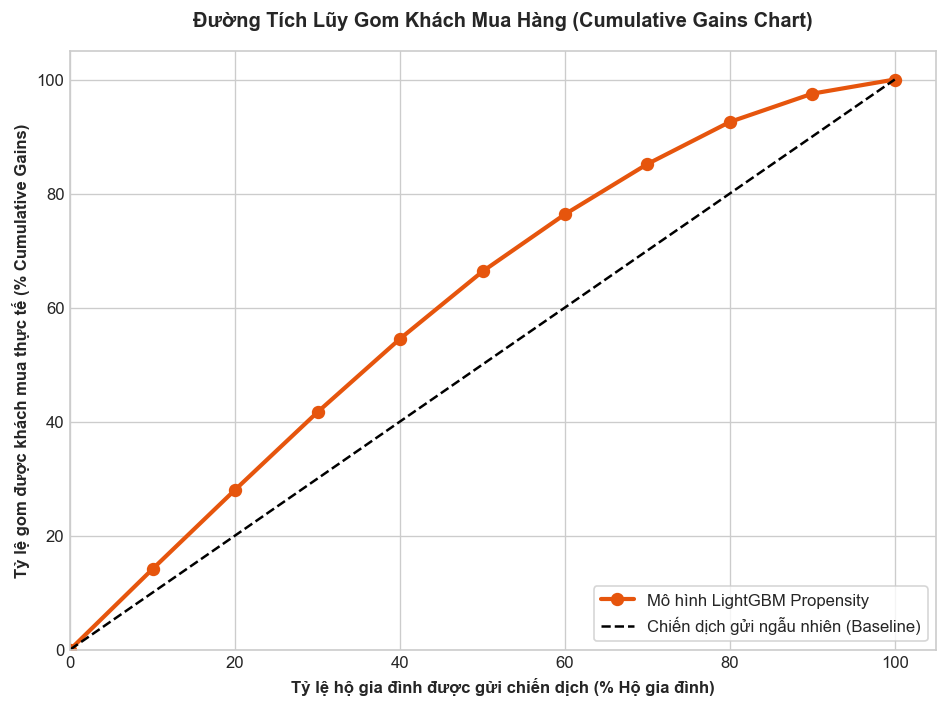

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))

cum_pct_hh = np.arange(10, 110, 10)
cum_gains = decile_df['cum_gains_pct'].values

ax.plot([0] + list(cum_pct_hh), [0] + list(cum_gains), 'o-', color='#e6550d', linewidth=2.5, markersize=7, label='Mô hình LightGBM Propensity')
ax.plot([0, 100], [0, 100], 'k--', linewidth=1.5, label='Chiến dịch gửi ngẫu nhiên (Baseline)')

ax.set_xlabel('Tỷ lệ hộ gia đình được gửi chiến dịch (% Hộ gia đình)', fontweight='bold')
ax.set_ylabel('Tỷ lệ gom được khách mua thực tế (% Cumulative Gains)', fontweight='bold')
ax.set_title('Đường Tích Lũy Gom Khách Mua Hàng (Cumulative Gains Chart)', pad=15, fontweight='bold')
ax.set_xlim(0, 105)
ax.set_ylim(0, 105)
ax.legend(frameon=True, facecolor='white', loc='lower right')
plt.tight_layout()
plt.show()


---
## 3. Mô Phỏng Lợi Nhuận Marketing (Marketing Campaign ROI Simulation)

Giả sử ngân sách tiếp thị:
- Chi phí gửi 1 ưu đãi / tin nhắn SMS / Voucher: **$1.50 / hộ**.
- Giá trị lợi nhuận biên trung bình nếu khách đi chợ: **$15.00 / giỏ hàng**.
- So sánh: Gửi đại trà toàn bộ 5,000 hộ vs Chỉ gửi cho nhóm Persuadable (Decile 5 - 8).


In [4]:
cost_per_contact = 1.50
margin_per_trip = 15.00

# 1. Kịch bản gửi đại trà (All 10 deciles)
total_hh = decile_df['households'].sum()
total_buyers = decile_df['actual_buyers'].sum()
cost_all = total_hh * cost_per_contact
rev_all = total_buyers * margin_per_trip
profit_all = rev_all - cost_all

# 2. Kịch bản gửi thông minh theo mô hình (Chỉ Decile 5 đến 8)
target_deciles = decile_df.iloc[4:8]
target_hh = target_deciles['households'].sum()
target_buyers = target_deciles['actual_buyers'].sum()
cost_smart = target_hh * cost_per_contact
rev_smart = target_buyers * margin_per_trip
profit_smart = rev_smart - cost_smart

print("💰 KẾT QUẢ MÔ PHỎNG TÀI CHÍNH:")
print(f" - Kịch bản 1 (Gửi đại trà toàn bộ 5,000 hộ): Chi phí = ${cost_all:,.0f} | Doanh thu = ${rev_all:,.0f} | Lợi nhuận ròng = ${profit_all:,.0f}")
print(f" - Kịch bản 2 (Gửi mục tiêu 2,000 hộ Decile 5-8): Chi phí = ${cost_smart:,.0f} (Tiết kiệm ${(cost_all-cost_smart):,.0f}) | Lợi nhuận = ${profit_smart:,.0f}")
print(f" 🎯 Tỷ suất hoàn vốn ROI Kịch bản 2: {profit_smart/cost_smart*100:.1f}%!")


💰 KẾT QUẢ MÔ PHỎNG TÀI CHÍNH:
 - Kịch bản 1 (Gửi đại trà toàn bộ 5,000 hộ): Chi phí = $7,500 | Doanh thu = $52,605 | Lợi nhuận ròng = $45,105
 - Kịch bản 2 (Gửi mục tiêu 2,000 hộ Decile 5-8): Chi phí = $3,000 (Tiết kiệm $4,500) | Lợi nhuận = $17,010
 🎯 Tỷ suất hoàn vốn ROI Kịch bản 2: 567.0%!
